Imports

In [29]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

Train and test split

In [30]:
# Training and Test Data Splitter
def train_test_split (df, i=0) :
    train = df.sample(frac=0.8, random_state=i) 
    test = df.drop(train.index)  
    xtrain = np.array(train.drop(columns=[0])) 
    xtest = np.array(test.drop(columns=[0]))  
    ytrain = np.array(train[0]) 
    ytest = np.array(test[0])  
    trainpos = train.index.to_numpy()  #keep a track of the position in the training split (for kernel slicing)
    testpos = test.index.to_numpy()
    return xtrain, xtest, ytrain, ytest, trainpos, testpos


Kernel Functions

In [31]:
def guass_kern (x1, x2, c=1, **kwargs):
    x1sq = np.sum(x1 ** 2, axis=1)[:, None]  # (n1, 1)
    x2sq = np.sum(x2 ** 2, axis=1)[None, :]  # (1, n2)
    num = x1sq + x2sq -2*(x1@x2.T)
    K = np.exp(-c * (num))
    return K

def poly_kern (x1, x2, d=1, **kwargs) :
    return (x1@x2.T) ** d

def block_kern (x1, x2, n1, n2, kernel_func, bSize = 250, **kwargs):
    '''
    Computes kernel in blocks/grid, memory efficient
    '''
    noBlocks1 = int(np.ceil(n1 / bSize)) #Amount of blocks to split x1 into
    noBlocks2 = int(np.ceil(n2 / bSize)) #Amount of blocks to split x2 into
    blocks1 = []
    blocks2 = []
    for b in range(noBlocks1): #Define the start and end positions of each block in x1
        start = b * bSize
        end = min((b + 1) * bSize, n1)
        blocks1.append((start, end))
    for b in range(noBlocks2): #Define the start and end positions of each block in x2
        start = b * bSize
        end = min((b + 1) * bSize, n2)
        blocks2.append((start, end))
    K = np.zeros((n1, n2)) #Initialise empty kernel of size n1 x n2
    for iStart, iEnd in blocks1: #For each block in x1
        for jStart, jEnd in blocks2: #For each block in x2
            #Compute the kernel values in blocks/grid as defined above
            K[iStart:iEnd, jStart:jEnd] = kernel_func(x1[iStart:iEnd, :], x2[jStart:jEnd, :], **kwargs)
    return K

def full_kern (x1, kernel_func, x2=None, bSize=250, **kwargs) :
    '''
    Computes the full Kernel, K(x1, x2)
    '''
    x1 = np.array(x1) 
    n1 =len(x1) 
    if x2 is None : #If no x2 provided, K(x1, x1)
        x2 = x1
        n2 = n1
    else: #If x2 provided, K(x1, x2)
        x2 = np.array(x2)
        n2 = len(x2)
    if n1 > bSize: #If length of x1 is greater than defined block size, compute kernel in blocks
        K = block_kern(x1, x2, n1, n2, kernel_func=kernel_func, **kwargs)
    else : #If length of x1 is less than defined block size, dont bother with computing kernel in blocks
        K = kernel_func(x1, x2, **kwargs) #Return full Kernel
    return K

Confusion Matrix functions

In [32]:
def confusion_matrix(y, yhat, Classes):
    '''
    Computes the confusion error matrix
    '''
    confMatrix = np.zeros((len(Classes), len(Classes))) #Initialise empty confusion matrix
    digitCounts = np.zeros(len(Classes)) #Initialise the amount of times each digit/class has been seen
    for i in range((len(y))):
        digitCounts[int(y[i])] = digitCounts[int(y[i])] + 1 #Increment digit count (tracks how many times its been seen)
        if yhat[i] != y[i]:
            #If prediciton is wrong, increment corresponding confusion erro matrix cell by one
            confMatrix[int(y[i]), int(yhat[i])] = confMatrix[int(y[i]), int(yhat[i])] + 1 
    for i in range((len(Classes))):
        if digitCounts[i] > 0: #If a digit has been seen at least once, find the average confusion error rate
            confMatrix[i, :] = confMatrix[i,:]/digitCounts[i]
    return confMatrix

def confusion_matrix_df(confMatrix, Classes):
    '''
    Formates the confusion error matrix as a dataframe with each cell containing Mean ± SD
    '''
    row, col,_ = confMatrix.shape
    df = np.empty((row, col), dtype=object) #Initalise empty dataframe
    for i in range(row):
        for j in range(col):
            me = confMatrix[i, j,0] #Extract Mean value
            sd = confMatrix[i, j,1] #Extract SD Value
            if me != 0: #Formatting
                me = float(f'{me:.{4}g}')
                me = np.format_float_scientific(me, precision=4, exp_digits=2, trim='k')
                me = me.replace('e', 'x10')
            if sd != 0:
                sd = float(f'{sd:.{4}g}')
                sd = np.format_float_scientific(sd, precision=4, exp_digits=2, trim='k')
                sd = sd.replace('e', 'x10')
            df[i,j] = f'{me}±{sd}'
    return pd.DataFrame(df, index=Classes, columns=Classes)

Predict and Update functions

In [33]:
def predict(alpha, xtrain_online, KRow) :
    '''
    Prediction step in Online Kernel Perceptron
    '''
    if len(alpha) == 0:
        return 0
    else:
        K = KRow[xtrain_online] #Extract Kernel values based on positions of errors during past online stream
        return np.array(alpha) @ K #Compute prediction 

def update_model (score, y, alpha, xtrain_online, t):
    '''
    Update step in online kernel perceptron
    '''
    if score >= 0: #If score >0 set prediction as target class
        y_hat = 1
    else: #Otherwise prediction as NOT target class
        y_hat = -1
    if y_hat != y:
        #If error in prediction, update alpha and add online position to xtrain_online
        #Only need to update on errors as only mistakes add a new support vector
        alpha.append(y)
        xtrain_online.append(t)

k class classifier one vs rest functions

In [34]:
def k_class_one_vs_rest_online_ker_perc (df, kernel_func, k_classes, epoch=1, split=None, K_precal_train = None, K_precal_test = None, confusion=False, **kwargs):
    '''
    Multiclass online kernel perceptron using One-vs-Rest.
    Trains k binary submodels (class k vs rest) with shared precomputed kernels
    and returns trained weights plus train/test error and optional confusion matrix.
    '''
    if split is None : #If no pre determined splits provided
        xtrain, xtest, ytrain, ytest, _, _ = train_test_split(df) #create test train splits
    else : #Otherwise use pre determined splits
        xtrain, xtest, ytrain, ytest = split
    y_pred_train, y_pred_test = [], [] #Initalise variables
    alpha = {k: [] for k in k_classes}
    xtrain_online = {k: [] for k in k_classes}
    if K_precal_train is None: #If no precalculated train kernel provided
        K_precal_train = full_kern(xtrain, kernel_func=kernel_func, **kwargs) #Calculate the train Kernel Matrix
    if K_precal_test is None: #If no precalculated test kernel provided
        K_precal_test = full_kern(xtest, kernel_func=kernel_func, x2=xtrain, **kwargs) #Caluculate the test Kernel matrix
    total_errors = 0
    #Training step
    for e in range(epoch) : #Loop through epochs
        epoch_errors = 0
        for i in range(len(xtrain)): #Loop through data points in an online fashion
            t = (e*len(xtrain)) + i #Keep a track of how many data points recieved online
            scores = []
            #Prediction step
            for k in k_classes : #Loop through k class submodels, trained to identify one class from the rest
                score = predict(alpha[k], xtrain_online[k], K_precal_train[i, :]) #For each submodel predict A @ K
                scores.append(score) #Keep a track of all the confidence scores the submodels predict
            y_hat = k_classes[np.argmax(scores)] #Pick the class from the submodel with the highest confidence
            y_pred_train.append(y_hat) #Keep track of the prediction
            if y_hat != ytrain[i]: #If the model makes a mistake, increment the count of total errors
                total_errors = total_errors + 1
            #Update step
            for j, k in enumerate(k_classes) : #Loop through all the submodels again
                if ytrain[i] == k: #Relabel datapoints {1,-1}
                    ylabel_class = 1 #Label ytrain[i] should have in submodel k
                else:
                    ylabel_class = -1
                #Call update function, updates if an error was made
                update_model(scores[j], ylabel_class, alpha[k], xtrain_online[k], i) 
    #train_error = total_errors / (t+1) #Compute the trianing error
    # Evaluate trained model on train data
    total_errors = 0
    for i in range(len(xtrain)):
        scores = []
        for k in k_classes:
            score = predict(alpha[k], xtrain_online[k], K_precal_train[i, :])
            scores.append(score)
        y_hat = k_classes[np.argmax(scores)]
        if y_hat != ytrain[i]:
            total_errors = total_errors + 1
    train_error = total_errors / len(xtrain)
    #Testing step
    total_errors = 0
    for i in range(len(xtest)): #Loop through test set in online fashion
        scores = []
        #Only do the predicition step
        for k in k_classes: 
            score = predict(alpha[k], xtrain_online[k], K_precal_test[i, :])
            scores.append(score)
        y_hat = k_classes[np.argmax(scores)]
        y_pred_test.append(y_hat)
        if y_hat != ytest[i]:
            total_errors = total_errors + 1
    test_error = total_errors / len(xtest) #Compute test errors
    if confusion == True:
        confMatrix = confusion_matrix(ytest, y_pred_test, k_classes) #Compute confusion error matrix
    else:
        confMatrix = None
    return alpha, y_pred_test, train_error, test_error, confMatrix

k class classifier one vs one functions

In [35]:
def k_class_one_vs_one_online_ker_perc (df, kernel_func, k_classes, epoch=1, split=None, K_precal_train = None, K_precal_test = None, confusion=False, **kwargs):
    '''
    Multiclass online kernel perceptron using One-vs-One.
    Trains a binary model for each class pair and predicts by pairwise voting
    with early-stopping to avoid unnecessary comparisons.
    '''
    if split is None :  #If no pre determined splits provided
        xtrain, xtest, ytrain, ytest, _, _ = train_test_split(df) #create test train splits
    else : #Otherwise use pre determined splits
        xtrain, xtest, ytrain, ytest = split
    y_pred_train, y_pred_test = [], [] #Initalise variables
    pairs = [(i, k) for i in k_classes for k in k_classes if k < i]
    alpha = {(i, k): [] for (i, k) in pairs}
    xtrain_online = {(i, k): [] for (i, k) in pairs}
    if K_precal_train is None: #If no precalculated train kernel provided
        K_precal_train = full_kern(xtrain, kernel_func=kernel_func, **kwargs) #Calculate the train Kernel Matrix
    if K_precal_test is None: #If no precalculated test kernel provided
        K_precal_test = full_kern(xtest, kernel_func=kernel_func, x2=xtrain, **kwargs) #Calculate the test Kernel Matrix
    #Training step
    total_errors = 0
    for e in range(epoch) :  #Loop through epochs
        epoch_errors = 0
        for i in range(len(xtrain)): #Loop through data points in an online fashion
            t = (e*len(xtrain)) + i #Keep a track of how many data points recieved online
            votes = np.zeros(len(k_classes)) #Initialise voting variables
            times_voted = np.zeros(len(k_classes))
            pair_scores = {}
            #Prediction step
            for (a,b) in pairs : #Loop through the pairs of submodels, trained to identify one class from one other
                pair_scores[(a,b)] = predict(alpha[(a,b)], xtrain_online[(a,b)], K_precal_train[i, :]) #For each submodel predict A @ K
                if pair_scores[(a,b)] >= 0 : #If the score is >=0 vote for class a, increment total votes for class a by 1
                    votes[a] = votes[a] + 1
                else : #If the score is >0 vote for the other class ie class b, increment total votes for class b by 1
                    votes[b] = votes[b] + 1
                times_voted[a] = times_voted[a] + 1 #Keep track of how many times each class has participated in a pairwise vote
                times_voted[b] = times_voted[b] + 1
                #How many submodels involving each class are still left to vote (each class participates in k-1 total pairwise comparisons)
                remaining_votes = (len(k_classes)-1) - times_voted 
                current_most_votes = np.argmax(votes) #Class with the current most votes
                max_possible = votes+ remaining_votes #Upper bound of the max votes each class COULD get if won all remaining pairwise comparisons
                max_possible[current_most_votes] = -np.inf #Exlucde current leader
                if votes[current_most_votes] > np.max(max_possible): 
                    # Stop early if the current leader cannot be overtaken by any remaining comparisons
                    break
            y_hat = k_classes[np.argmax(votes)] #Predict the class with the most votes
            y_pred_train.append(y_hat) #Keep track of predictions
            if y_hat != ytrain[i]:
                total_errors = total_errors + 1
            #Update Step
            for (a,b) in pairs: #Loop through all the submodels again
                if ytrain[i] in (a,b): #If datapoint is relevant to the pair
                    if ytrain[i] == a:#Relabel datapoints {1,-1}
                        ylabel_class =1 #Label ytrain[i] should have in submodel k
                    else :
                        ylabel_class =-1
                    if (a, b) not in pair_scores: #If score wasnt evalauted earlier, compute it now
                        pair_scores[(a, b)] = predict(alpha[(a, b)], xtrain_online[(a, b)], K_precal_train[i, :])
                    update_model(pair_scores[(a,b)], ylabel_class, alpha[(a,b)], xtrain_online[(a,b)], i) #Update model
    #train_error = total_errors / (t+1) #Compute train error
    # Evaluate trained model on train data
    total_errors = 0
    for i in range(len(xtrain)):
        votes = np.zeros(len(k_classes))
        for (a, b) in pairs:
            score = predict(alpha[(a, b)], xtrain_online[(a, b)], K_precal_train[i, :])
            if score >= 0:
                votes[a] += 1
            else:
                votes[b] += 1
        y_hat = k_classes[np.argmax(votes)]
        if y_hat != ytrain[i]:
            total_errors = total_errors + 1
    train_error = total_errors / len(xtrain)
    #Testing step
    total_errors = 0
    for i in range(len(xtest)):
        votes = np.zeros(len(k_classes))
        #Only do the Prediction step
        for (a,b) in pairs:
            score = predict(alpha[(a, b)], xtrain_online[(a, b)], K_precal_test[i, :])
            if score >= 0:
                votes[a] = votes[a] + 1
            else:
                votes[b] = votes[b] + 1
        y_hat = k_classes[np.argmax(votes)]
        y_pred_test.append(y_hat)
        if y_hat != ytest[i]:
            total_errors = total_errors + 1
    test_error = total_errors / len(xtest) #Compute the test error
    if confusion == True:
        confMatrix = confusion_matrix(ytest, y_pred_test, k_classes) #Compute confusion error matrix
    else:
        confMatrix = None
    return alpha, y_pred_test, train_error, test_error, confMatrix

Cross Validation Function

In [36]:
def cross_validation(xtrain, ytrain, folds, algorithm_func, kernel_func, paramlist, k_classes, epoch_lim=1, **kwargs):
    '''
    Perform K fold cross validation over a list of kernel parameters.
    For each parameter train on K-1 folds and evaluate on the held out fold
    returning the parameter with the lowest mean test error and the full table
    of fold averaged results.
    '''
    positions = np.arange(len(xtrain)) #Array of index positions of xtrain
    foldPositions = np.array_split(positions, folds) #Split index positions into folds
    K_precal = {p: full_kern(xtrain, kernel_func=kernel_func, d=p, c=p) for p in paramlist} #Precalculate kernels
    results = np.zeros((folds, len(paramlist), 1)) # Initialise results
    for j, p in enumerate(paramlist): #Loop through parameter values
        K_train_full = K_precal[p] #Full kernel matrix for parameter p
        for i in range(folds): # Loop through folds
            xtrain_foldPos = np.concatenate([foldPositions[f] for f in range(folds) if f != i]) #Train on all folds apart from fold i
            xtest_foldPos = foldPositions[i] #Test fold is fold i
            K_train = K_train_full[np.ix_(xtrain_foldPos, xtrain_foldPos)] #Slice kernel matrices for this fold
            K_test = K_train_full[np.ix_(xtest_foldPos, xtrain_foldPos)] 
            ytrain_fold = ytrain[xtrain_foldPos] #Slice labels for this fold
            ytest_fold = ytrain[xtest_foldPos]
            xtrain_fold = xtrain[xtrain_foldPos]
            xtest_fold = xtrain[xtest_foldPos]
            split_fold = (xtrain_fold, xtest_fold, ytrain_fold, ytest_fold) 
            #Train model and compute test error
            _, _, _, me_test, _ = algorithm_func(None, kernel_func, k_classes, epoch=epoch_lim, split=split_fold,
                                                  K_precal_train=K_train, K_precal_test=K_test, d=p, c=p)
            results[i, j, 0] = me_test #Store test error for this fold
    avgme_test = np.mean(results[:, :, 0], axis=0) #Copmute mean test error for each parameter
    avgme_df = pd.DataFrame({'Param': paramlist, 'avg_me_test_fold': avgme_test})
    avgme_df = avgme_df.sort_values(by ='avg_me_test_fold', ascending=True) #Sort mean test errors from low to high
    min_me = avgme_df.iloc[0] #Select row with smallest mean test error
    return float(min_me['Param']), min_me['avg_me_test_fold'], avgme_df #Return df with minimum mean test error parameter

r sims function

In [37]:
def r_sims_k_class_ker_perc(df, r, k_classes, param, algorithm_func=k_class_one_vs_rest_online_ker_perc, kernel_func=poly_kern, epoch_lim = 1, splits=None,  crossVal=False, confusion=False, **kwargs) :
    '''
    Runs r repetitions of k class kernel perceptron training with different splits.
    Returns average train/test error across runs (and confusion matrices if requested).
    '''
    #Initalise variables
    if crossVal == True:
        results = np.zeros((r, 1, 2))
    else:
        results=np.zeros((r, len(param),2))
    if confusion == True:
        confMatrix = np.zeros((r, len(k_classes), len(k_classes)))
    else :
        confMatrix = None
    fig, ax = None, None
    tested_counts = np.zeros(len(df))
    error_counts = np.zeros(len(df))
    y_pred_record = np.zeros(len(df))
    best_params = []
    for i in range(r): #Loop through runs
        if splits is None: #If no pre determined splits provided
            xtrain, xtest, ytrain, ytest, trainpos, testpos = train_test_split(df, i) #Create splits
            split = (xtrain, xtest, ytrain.copy(), ytest.copy())
        else: #Otherwise use pre determined splits
            xtrain, xtest, ytrain, ytest, trainpos, testpos = splits[i]
            split = (xtrain, xtest, ytrain.copy(), ytest.copy())
        if crossVal == True:
            #Select best kernel parameter using cross validation
            minparam, minparam_testerror, crossValdf= cross_validation(xtrain, ytrain, 5, algorithm_func, kernel_func, param, k_classes, epoch_lim=epoch_lim)
            best_params.append({
                "run": int(i),
                "best_param": float(minparam),
                "test_error": minparam_testerror
            })
            #Train model using best parameter
            alpha, y_pred_test, me_train, me_test, confMatrix_r = algorithm_func(None, kernel_func, k_classes, epoch=epoch_lim, split=split, confusion=confusion, d=minparam, c=minparam)
            results[i, 0, 0] = me_train #Store train and test error
            results[i, 0, 1] = me_test
            if confusion == True:
                confMatrix[i] = confMatrix_r #Compute confusion matrix for this run
        else : #Evaluate all parameter values
            minparam = None
            for j, p in enumerate(param): 
                alpha, y_pred_test, me_train, me_test, _ = algorithm_func(None, kernel_func, k_classes, epoch = epoch_lim, split=split, d=p, c=p)
                results[i,j,0] = me_train 
                results[i,j,1] = me_test
        tested_counts[testpos] = tested_counts[testpos] + 1 #Update hard sample statistics
        errors = (np.array(y_pred_test) != ytest).astype(int)
        error_counts[testpos] = error_counts[testpos] + errors
        y_pred_record[testpos] = y_pred_test
    hard = error_counts / np.maximum(tested_counts, 1) #Identify 5 hardest to classify samples
    hard[tested_counts == 0] = -1
    h = np.argsort(hard)[::-1][:5]
    hard = df.iloc[h, :]
    hard_pred = y_pred_record[h]
    avgme_train= np.mean(results[:, :, 0], axis=0) #Compute averages + SD
    avgsde_train = np.std(results[:, :, 0], axis=0)
    avgme_test = np.mean(results[:, :, 1], axis=0)
    avgsde_test = np.std(results[:, :, 1], axis=0)
    if crossVal == True:
        avgme_df = pd.DataFrame({'param': minparam, 'avg_me_train': avgme_train, 'avg_me_test': avgme_test, 'avg_me_train_sd': avgsde_train, 'avg_me_test_sd': avgsde_test})
    else:
        avgme_df = pd.DataFrame({'param': param, 'avg_me_train': avgme_train, 'avg_me_test': avgme_test, 'avg_me_train_sd': avgsde_train,'avg_me_test_sd': avgsde_test})
    if confusion == True:
        avgconfMatrix = np.mean(confMatrix, axis=0)
        sdconfMatrix = np.std(confMatrix, axis=0)
        fullconfMatrix = np.stack((avgconfMatrix, sdconfMatrix), axis=2)
        return avgme_df, fullconfMatrix, hard, hard_pred, best_params
    else :
        return avgme_df, hard, hard_pred, best_params

Plotting functions

In [38]:
def plot_pixel_images(hard, hard_pred):
    '''
    Plot the hardest misclassified samples as 16×16 grayscale images,
    showing their true label, dataset index, and model prediction.
    '''
    n = len(hard)
    fig, ax = plt.subplots(1, n, figsize=(3*n, 3))
    for j, (i, row) in enumerate(hard.iterrows()):
        num = row.iloc[1:].values.reshape(16, 16)
        label = int(row.iloc[0])
        ax[j].imshow(num, cmap="gray")
        ax[j].set_title(f"Label {label}\nIndex {i}\nModel Pred {int(hard_pred[j])}")
        ax[j].axis("off")
    return fig, ax

def plot_gaussian_param_curve(avgme_df: pd.DataFrame, *, title: str, show_as_powers: bool = False, b_values: list[int] | None = None):
    '''
    Plot test error versus Gaussian kernel parameter c, with optional
    tick labels shown in 2^{-b/2} form for log-scale visualisation.
    '''
    fig, ax = plt.subplots(figsize=(6, 4))
    x = avgme_df["param"].values
    y = avgme_df["avg_me_test"].values
    ax.plot(x, y, marker="o", linewidth=2)
    ax.set_ylabel("Test error rate")
    ax.set_xlabel("Gaussian kernel parameter $c$")
    ax.set_title(title)
    if show_as_powers:
        if b_values is None:
            raise ValueError("b_values must be provided when show_as_powers=True")
        labels = [rf"$2^{{-{b}/2}}$" for b in b_values]
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=45)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig, ax

Main

Q2 Implementation of k class classifier one vs rest

In [39]:
url = 'http://www0.cs.ucl.ac.uk/staff/M.Herbster/SL/misc/zipcombo.dat'
df = pd.read_csv(url, sep=r"\s+", header=None)
dftest = df.sample(frac=0.15, random_state=0).reset_index(drop=True)
print(df.head())


   0    1    2    3      4      5      6      7      8      9    ...    247  \
0  6.0 -1.0 -1.0 -1.0 -1.000 -1.000 -1.000 -1.000 -0.631  0.862  ...  0.304   
1  5.0 -1.0 -1.0 -1.0 -0.813 -0.671 -0.809 -0.887 -0.671 -0.853  ... -0.671   
2  4.0 -1.0 -1.0 -1.0 -1.000 -1.000 -1.000 -1.000 -1.000 -1.000  ... -1.000   
3  7.0 -1.0 -1.0 -1.0 -1.000 -1.000 -0.273  0.684  0.960  0.450  ... -0.318   
4  3.0 -1.0 -1.0 -1.0 -1.000 -1.000 -0.928 -0.204  0.751  0.466  ...  0.466   

     248    249    250    251    252    253    254    255  256  
0  0.823  1.000  0.482 -0.474 -0.991 -1.000 -1.000 -1.000 -1.0  
1 -0.671 -0.033  0.761  0.762  0.126 -0.095 -0.671 -0.828 -1.0  
2 -1.000 -1.000 -0.109  1.000 -0.179 -1.000 -1.000 -1.000 -1.0  
3  1.000  0.536 -0.987 -1.000 -1.000 -1.000 -1.000 -1.000 -1.0  
4  0.639  1.000  1.000  0.791  0.439 -0.199 -0.883 -1.000 -1.0  

[5 rows x 257 columns]


k class classifier one vs rest with polynomial kernel example

In [40]:
print('Q2')
epoch = 5
Classes = [0,1,2,3,4,5,6,7,8,9]
alpha, y_pred_test, train_errors, test_errors, _ = k_class_one_vs_rest_online_ker_perc(df, poly_kern, Classes, epoch)
print('K class kernel perceptron classifier, one vs rest')
print('Polynomial Kernel : 1 run')
print('Target classes 0-9')
print(f'Train error = {train_errors}, Test error = {test_errors}')

Q2
K class kernel perceptron classifier, one vs rest
Polynomial Kernel : 1 run
Target classes 0-9
Train error = 0.06332347405216456, Test error = 0.08118279569892473


Q3 k class classifier one vs rest with polynomial kernel averaged over 20 runs

In [41]:
print('Q3')
runs = 20
rsplits = []
for i in range(runs):
    rsplits.append(train_test_split(df, i))
d=[1,2,3,4,5,6,7]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, _, _, _ = r_sims_k_class_ker_perc(df, runs, Classes, param=d, epoch_lim = epoch, splits=rsplits)
print('K class kernel perceptron classifier, one vs rest')
print(f'Polynomial Kernel : {runs} runs')
print(avgme_df)

Q3
K class kernel perceptron classifier, one vs rest
Polynomial Kernel : 20 runs
   param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0      1      0.075094     0.095806         0.018828        0.018313
1      2      0.007220     0.037823         0.003398        0.006907
2      3      0.001956     0.030726         0.000858        0.005199
3      4      0.000739     0.028387         0.000333        0.004558
4      5      0.000545     0.028414         0.000459        0.003710
5      6      0.000316     0.027339         0.000136        0.005409
6      7      0.000329     0.028441         0.000124        0.003954


Q4 Cross Validation of k class classifier one vs rest with polynomial kernel using 5 folds

In [42]:
print('Q4')
runs = 20
d=[1,2,3,4,5,6,7]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, avgconfMatrix, hard, hard_pred, best_params = r_sims_k_class_ker_perc(df, runs, Classes, param=d, epoch_lim=epoch, splits=rsplits, crossVal=True, confusion=True)
print('K class kernel perceptron classifier, one vs rest')
print(f'Polynomial Kernel : {runs} runs with cross validation')
print(avgme_df)

Q4
K class kernel perceptron classifier, one vs rest
Polynomial Kernel : 20 runs with cross validation
   param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0    5.0      0.000511     0.027124          0.00037        0.003155


Q5 Confusion Matrix of k class classifier one vs rest with polynomial kernel and 5 fold cross validation averaged over 20 runs

In [43]:
print('Q5')
print('Average Confusion Matrix')
avgconfMatrix = confusion_matrix_df(avgconfMatrix, Classes)
print(avgconfMatrix)

Q5
Average Confusion Matrix
                         0                        1                        2  \
0                  0.0±0.0    3.3x10-04±9.911x10-04  9.536x10-04±1.767x10-03   
1  2.101x10-04±9.157x10-04                  0.0±0.0  5.691x10-04±1.355x10-03   
2  4.299x10-03±4.241x10-03   2.632x10-03±3.77x10-03                  0.0±0.0   
3  2.269x10-03±4.357x10-03  9.107x10-04±2.175x10-03   7.667x10-03±8.54x10-03   
4                  0.0±0.0  4.057x10-03±4.805x10-03  5.775x10-03±5.164x10-03   
5  8.311x10-03±1.066x10-02   1.04x10-03±2.476x10-03   4.44x10-03±5.417x10-03   
6  7.597x10-03±6.494x10-03  2.103x10-03±3.471x10-03  1.254x10-03±2.525x10-03   
7   5.65x10-04±1.695x10-03   2.69x10-03±4.015x10-03   3.48x10-03±4.244x10-03   
8  6.797x10-03±6.307x10-03  4.841x10-03±6.879x10-03  4.337x10-03±4.098x10-03   
9  1.825x10-03±3.854x10-03  2.976x10-04±1.297x10-03  1.514x10-03±3.229x10-03   

                         3                        4                        5  \
0  2.272x10

Q6 5 Hard to Predict Samples : k class classifier one vs rest with polynomial kernel and 5 fold cross validation averaged over 20 runs

Q6
hard


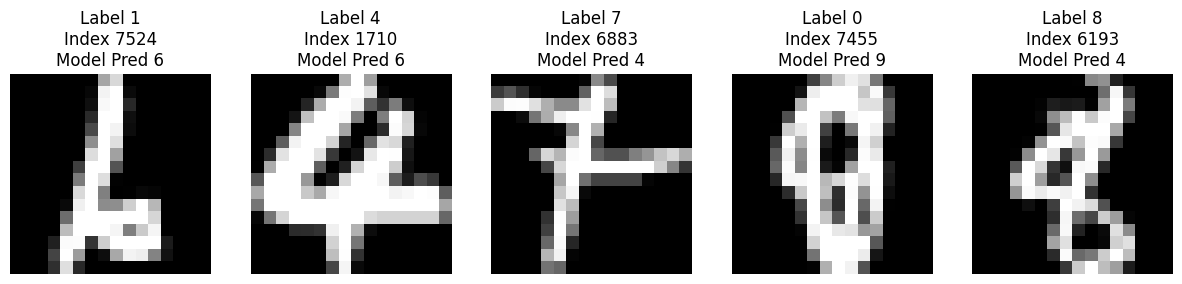

In [44]:
print('Q6')
print('hard')
fig, ax = plot_pixel_images(hard, hard_pred)
plt.show()
plt.close()

Q7

Gaussian kernel parameter choice: brief justification

To identify a suitable value for the Gaussian kernel parameter ${c}$, I use a progressive search strategy. 
The idea is to begin with a wide range of values to locate the region where the kernel behaves sensibly, and then refine the search within that interval.

For the finer exploration I used a log base ${2}$ form, ${c={2^{−b/2}}}$.

This leads to a set of well targeted candidate ${c}$ values for the experiments that follow.

Q7
(a) Explaining how S was chosen
c = [0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10]
K class kernel perceptron classifier, one vs rest
Guassian Kernel : 1 runs
    param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0   0.005      0.005376     0.086022              0.0             0.0
1   0.010      0.001792     0.057348              0.0             0.0
2   0.050      0.000000     0.086022              0.0             0.0
3   0.100      0.000896     0.129032              0.0             0.0
4   0.500      0.000000     0.100358              0.0             0.0
5   1.000      0.000000     0.100358              0.0             0.0
6   5.000      0.000000     0.103943              0.0             0.0
7  10.000      0.000000     0.354839              0.0             0.0
c = [0.03125, 0.02209708691207961, 0.015625, 0.011048543456039806, 0.0078125, 0.005524271728019903, 0.00390625, 0.0027621358640099515, 0.001953125, 0.0013810679320049757]
K class kernel perceptron classifier, one vs 

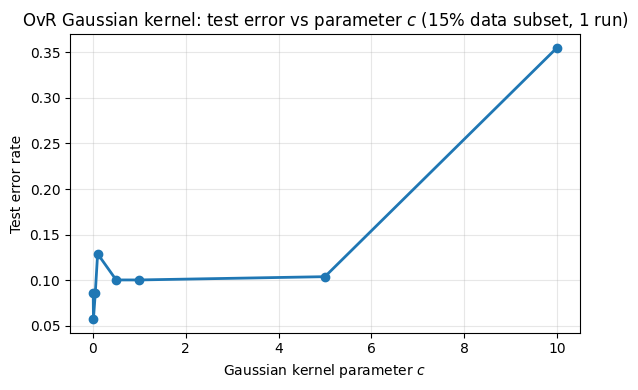

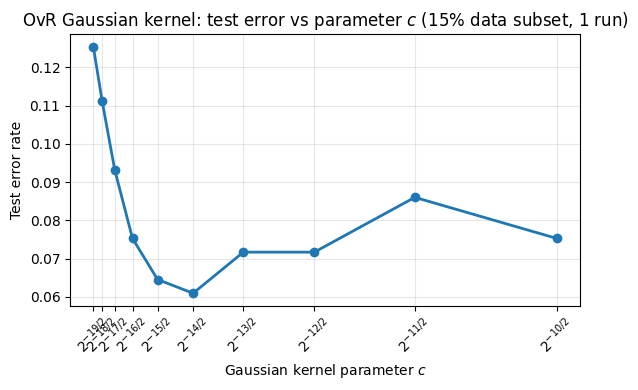

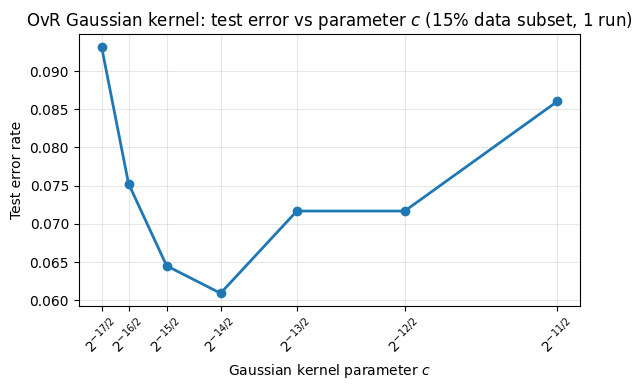

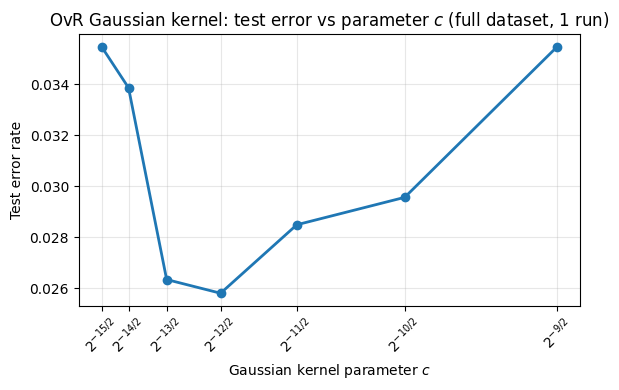

In [45]:
print('Q7')
print('(a) Explaining how S was chosen')
runs=1
c = [0.005, 0.01, 0.05, 0.1, 0.5 ,1, 5, 10]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, _ , _, _ = r_sims_k_class_ker_perc(dftest, runs, Classes, param=c, kernel_func=guass_kern, epoch_lim= epoch)
print(f'c = {c}')
print('K class kernel perceptron classifier, one vs rest')
print(f'Guassian Kernel : {runs} runs')
print(avgme_df)
fig, ax = plot_gaussian_param_curve(
    avgme_df,
    title="OvR Gaussian kernel: test error vs parameter $c$ (15% data subset, 1 run)",
    show_as_powers=False
)
runs=1
c = [2**(-b/2) for b in range(10, 20)]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, _ , _, _ = r_sims_k_class_ker_perc(dftest, runs, Classes, param=c, kernel_func=guass_kern, epoch_lim= epoch)
print(f'c = {c}')
print('K class kernel perceptron classifier, one vs rest')
print(f'Guassian Kernel : {runs} runs')
print(avgme_df)
b_vals = list(range(10, 20))
fig, ax = plot_gaussian_param_curve(
    avgme_df,
    title="OvR Gaussian kernel: test error vs parameter $c$ (15% data subset, 1 run)",
    show_as_powers=True,
    b_values=b_vals
)
runs=1
c = [2**(-b/2) for b in range(11, 18)]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, _ , _, _ = r_sims_k_class_ker_perc(dftest, runs, Classes, param=c, kernel_func=guass_kern, epoch_lim= epoch)
print(f'c = {c}')
print('K class kernel perceptron classifier, one vs rest')
print(f'Guassian Kernel : {runs} runs')
print(avgme_df)
b_vals = list(range(11, 18))
fig, ax = plot_gaussian_param_curve(
    avgme_df,
    title="OvR Gaussian kernel: test error vs parameter $c$ (15% data subset, 1 run)",
    show_as_powers=True,
    b_values=b_vals
)
runs=1
c = [2**(-b/2) for b in range(9, 16)]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, _ , _, _ = r_sims_k_class_ker_perc(df, runs, Classes, param=c, kernel_func=guass_kern, epoch_lim= epoch)
print(f'c = {c}')
print('K class kernel perceptron classifier, one vs rest')
print(f'Guassian Kernel : {runs} runs')
print(avgme_df)
b_vals = list(range(9, 16))
fig, ax = plot_gaussian_param_curve(
    avgme_df,
    title="OvR Gaussian kernel: test error vs parameter $c$ (full dataset, 1 run)",
    show_as_powers=True,
    b_values=b_vals
)

(b) k class classifier one vs rest with Guassian kernel averaged over 20 runs

In [46]:
print('(b)')
runs = 20
# c= np.linspace(0.045, 0.055, 50).tolist()
c = [2**(-b/2) for b in range(9, 16)]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, _ , _, _ = r_sims_k_class_ker_perc(df, runs, Classes, param=c, kernel_func=guass_kern, epoch_lim= epoch, splits=rsplits)
print('K class kernel perceptron classifier, one vs rest')
print(f'Guassian Kernel : {runs} runs')
print(avgme_df)

(b)
K class kernel perceptron classifier, one vs rest
Guassian Kernel : 20 runs
      param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0  0.044194      0.000242     0.035565         0.000362        0.005263
1  0.031250      0.000323     0.029677         0.000424        0.004419
2  0.022097      0.000249     0.026505         0.000191        0.003714
3  0.015625      0.000316     0.025430         0.000149        0.004045
4  0.011049      0.000504     0.026048         0.000244        0.002957
5  0.007812      0.001008     0.029194         0.000758        0.003627
6  0.005524      0.003496     0.033011         0.001288        0.005274


(c) Cross Validation of k class classifier one vs rest with Guassian kernel using 5 folds

In [47]:
print('(c)')
runs = 20
# c= np.linspace(0.045, 0.055, 50).tolist()
c = [2**(-b/2) for b in range(9, 16)]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, avgconfMatrix, hard, hard_pred, best_params = r_sims_k_class_ker_perc(df, runs, Classes, param=c, kernel_func=guass_kern, epoch_lim=epoch, splits=rsplits, crossVal=True, confusion=True)
print('K class kernel perceptron classifier, one vs rest')
print(f'Guassian Kernel : {runs} runs with cross validation')
print(avgme_df)

(c)
K class kernel perceptron classifier, one vs rest
Guassian Kernel : 20 runs with cross validation
      param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0  0.022097      0.000336     0.025242         0.000183        0.003927


Confusion Matrix of k class classifier one vs rest with Guassian kernel and 5 fold cross validation averaged over 20 runs

In [48]:

print('Average Confusion Matrix')
avgconfMatrix = confusion_matrix_df(avgconfMatrix, Classes)
print(avgconfMatrix)

Average Confusion Matrix
                         0                        1                        2  \
0                  0.0±0.0  3.198x10-04±9.606x10-04   1.446x10-03±2.12x10-03   
1  2.101x10-04±9.157x10-04                  0.0±0.0  7.724x10-04±1.546x10-03   
2  3.107x10-03±4.267x10-03  2.138x10-03±2.633x10-03                  0.0±0.0   
3  2.738x10-03±4.841x10-03  9.633x10-04±2.307x10-03  6.504x10-03±5.668x10-03   
4  8.662x10-04±2.063x10-03  3.483x10-03±4.933x10-03  5.121x10-03±7.524x10-03   
5   7.975x10-03±8.55x10-03  6.857x10-04±2.059x10-03   4.51x10-03±4.567x10-03   
6  7.752x10-03±9.002x10-03   1.851x10-03±2.84x10-03    2.117x10-03±3.4x10-03   
7                  0.0±0.0    2.4x10-03±3.482x10-03  3.134x10-03±5.449x10-03   
8  6.773x10-03±4.826x10-03  3.153x10-03±5.265x10-03  4.319x10-03±4.785x10-03   
9  2.874x10-04±1.253x10-03  6.266x10-04±1.882x10-03   1.82x10-03±3.326x10-03   

                         3                        4                        5  \
0  2.065x10-03

5 Hard to Predict Samples : k class classifier one vs rest with Guassian kernel and 5 fold cross validation averaged over 20 runs

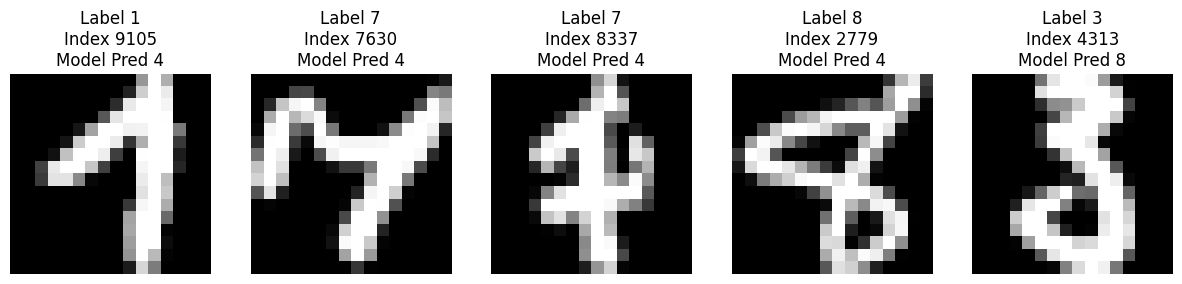

In [49]:
fig, ax = plot_pixel_images(hard, hard_pred)
plt.show()
plt.close()

Q8

(b) k class classifier one vs one with polynomial kernel averaged over 20 runs

In [50]:
print('(b)')
runs = 20
d=[1,2,3,4,5,6,7]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, _, _, _ = r_sims_k_class_ker_perc(df, runs, Classes, param=d, algorithm_func=k_class_one_vs_one_online_ker_perc, epoch_lim = epoch, splits=rsplits)
print('K class kernel perceptron classifier, one vs one')
print(f'Polynomial Kernel : {runs} runs')
print(avgme_df)

(b)
K class kernel perceptron classifier, one vs one
Polynomial Kernel : 20 runs
   param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0      1      0.045624     0.072823         0.007007        0.010309
1      2      0.007354     0.041075         0.003205        0.004955
2      3      0.002185     0.034086         0.000902        0.004762
3      4      0.001297     0.033468         0.000914        0.004690
4      5      0.000968     0.033226         0.001474        0.005343
5      6      0.000450     0.033441         0.000222        0.005223
6      7      0.000605     0.034597         0.001056        0.004258


(c) Cross Validation of k class classifier one vs one with polynomial kernel using 5 folds

In [51]:
print('(c)')
runs = 20
d=[1,2,3,4,5,6,7]
Classes = [0,1,2,3,4,5,6,7,8,9]
avgme_df, avgconfMatrix, hard, hard_pred, best_params = r_sims_k_class_ker_perc(df, runs, Classes, param=d, algorithm_func=k_class_one_vs_one_online_ker_perc, epoch_lim = epoch, splits=rsplits, crossVal=True, confusion=True)
print('K class kernel perceptron classifier, one vs one')
print(f'Polynomial Kernel : {runs} runs with cross validation')
print(avgme_df)

(c)
K class kernel perceptron classifier, one vs one
Polynomial Kernel : 20 runs with cross validation
   param  avg_me_train  avg_me_test  avg_me_train_sd  avg_me_test_sd
0    6.0       0.00115     0.032796          0.00099        0.005049


Confusion Matrix of k class classifier one vs one with polynomial kernel and 5 fold cross validation averaged over 20 runs

In [52]:
print('Average Confusion Matrix')
avgconfMatrix = confusion_matrix_df(avgconfMatrix, Classes)
print(avgconfMatrix)

Average Confusion Matrix
                         0                        1                        2  \
0                  0.0±0.0                  0.0±0.0  2.722x10-03±2.325x10-03   
1                  0.0±0.0                  0.0±0.0   1.916x10-04±8.35x10-04   
2  5.597x10-03±4.559x10-03  2.182x10-03±2.682x10-03                  0.0±0.0   
3   3.75x10-03±4.968x10-03  6.161x10-04±1.849x10-03  9.906x10-03±9.739x10-03   
4  2.042x10-03±2.786x10-03  5.261x10-03±6.389x10-03  8.163x10-03±5.105x10-03   
5  1.841x10-02±1.522x10-02                  0.0±0.0  4.422x10-03±5.296x10-03   
6  9.474x10-03±6.719x10-03  2.735x10-03±3.579x10-03  2.403x10-03±4.802x10-03   
7  3.226x10-04±1.406x10-03  4.566x10-03±4.565x10-03  4.727x10-03±5.659x10-03   
8  8.601x10-03±7.735x10-03  7.817x10-03±6.758x10-03  6.077x10-03±6.563x10-03   
9    1.51x10-03±2.62x10-03  1.239x10-03±2.482x10-03  1.227x10-03±2.458x10-03   

                         3                        4                        5  \
0  2.253x10-03

5 Hard to Predict Samples : k class classifier one vs one with polynomial kernel and 5 fold cross validation averaged over 20 runs

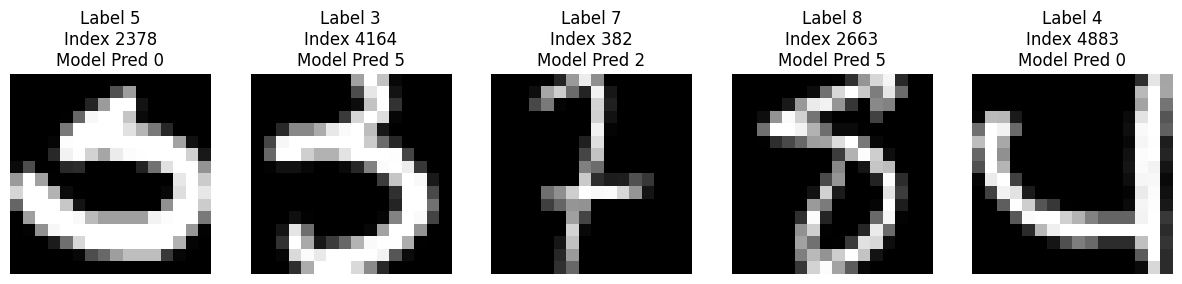

In [53]:
fig, ax = plot_pixel_images(hard, hard_pred)
plt.show()
plt.close()